# Telco Customer Churn Prediction
### Machine Learning for Developers (CAI2C08) - Project Submission

| | |
|---|---|
| **Name** | Mohammed Hannan Noor |
| **Student ID** | XXXXXXXX |
| **Class / Group** | C25U02 |
| **Module** | CAI2C08 Machine Learning for Developers |
| **School** | School of Informatics & IT, Temasek Polytechnic |

---

## Declaration of Originality

I declare that this submission is my own work and that all external sources have been acknowledged.

**Use of Generative AI:** Generative AI tools were used to assist with code structuring, debugging and
documentation. All modelling decisions and analysis were reviewed, verified and understood by me.

**Dataset:** Telco Customer Churn (public IBM sample).

# Libraries

In [1]:
## Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

# 1. Business Understanding

**Goal:** Predict whether a telecom customer will **churn** (cancel their service).

**Why this matters:**
- Keeping an existing customer is far cheaper than winning a new one, so churn hits revenue directly.
- A model that flags at-risk customers lets the business act early with retention offers before they leave.
- Knowing *which factors* drive churn (contract type? tenure? service issues?) tells the retention team where to focus.

**Type of problem:** Binary classification. The target (`Churn`) is Yes or No, not a continuous number.

**Data source:** Telco Customer Churn, a public IBM sample of 7,043 telecom customers.

## 1.1 Assumptions and Scope

Stating these up front, because each one shapes how the results should be read.

**About the data**

1. **The dataset is representative of the customer base.** It is a public IBM sample of 7,043
   customers. We assume the churn rate (26.5%) and the mix of contracts, services and payment methods
   reflect the business we are modelling for.
2. **`Churn = Yes` means a genuine cancellation**, not a temporary suspension or a plan change. The
   dataset does not distinguish between these.
3. **Every row is one distinct customer**, with no duplicates or household grouping.
4. **The eleven blank `TotalCharges` values are structurally absent, not missing at random.** All
   eleven have `tenure = 0`, so they are customers who have not been billed yet. We drop them rather
   than impute, because imputing would invent a billing history that does not exist.

**About the problem**

5. **The data is a single snapshot with no time dimension.** We are predicting *who currently looks
   like a churner*, not forecasting *when* someone will leave. Behavioural changes that often precede
   churn are therefore invisible to the model.
6. **Missing a churner costs more than a false alarm.** A wasted retention offer is cheaper than
   losing a customer, which is why we track recall on the churn class alongside Weighted F1. We do not
   have the actual costs, so we report the balanced 0.5 operating point and treat the threshold as a
   lever the business can set once those costs are known.

**About the modelling**

7. **The train/test split is a fair proxy for future customers.** We stratify to preserve the churn
   rate and never let the test set influence training or tuning.
8. **Relationships are associations, not causes.** The model learns that customers on two-year
   contracts churn less; it cannot show that *moving* someone onto one would cause that reduction.
   Any what-if figures, including those in the deployed app, should be read as modelled associations.
9. **The customer base stays broadly stable.** A model trained on this snapshot will degrade if
   pricing, competitors or the product mix change materially, so it would need periodic retraining.


# 2. Data Understanding

Before we model anything, we need to *know our data*. Three questions to keep asking:

1. **What does each column mean?** (How was it measured? What units?)
2. **What does the data look like?** (Types, ranges, missing values, class balance.)
3. **How are variables related?** (Especially: how does each feature relate to churn?)

Skipping this step is the #1 cause of bad models. Garbage in, garbage out.

## 2.1 Load dataset

We use `pandas.read_csv()` to load the file into a **DataFrame**, a table-like structure that is the workhorse of
data analysis in Python. Each row is one customer; each column is an attribute of their account.

| Column | Description |
|---|---|
| `customerID` | Unique customer identifier (not a feature) |
| `gender` | Male or Female |
| `SeniorCitizen` | 1 if the customer is a senior citizen, else 0 |
| `Partner` | Yes if the customer has a partner |
| `Dependents` | Yes if the customer has dependents |
| `tenure` | Number of months the customer has stayed |
| `PhoneService` | Yes if the customer has phone service |
| `MultipleLines` | Whether the customer has multiple phone lines |
| `InternetService` | DSL, Fiber optic, or No internet |
| `OnlineSecurity` | Whether they have the online-security add-on |
| `OnlineBackup` | Whether they have online backup |
| `DeviceProtection` | Whether they have device protection |
| `TechSupport` | Whether they have tech support |
| `StreamingTV` | Whether they stream TV |
| `StreamingMovies` | Whether they stream movies |
| `Contract` | Month-to-month, One year, or Two year |
| `PaperlessBilling` | Yes if billing is paperless |
| `PaymentMethod` | How the customer pays |
| `MonthlyCharges` | Current monthly charge (numeric) |
| `TotalCharges` | Total amount charged to date (numeric) |
| `Churn` | **Target**, Yes if the customer left, else No |

In [2]:
## Read the CSV file into a pandas DataFrame
FILE_PATH = "churn.csv"
df = pd.read_csv(FILE_PATH)

## Display the first few rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2.2 Summary Statistics

Three quick checks tell us a lot about the data before we touch a single chart:

* `df.info()` gives the column data types and non-null counts (spots categoricals and missing values).
* `df.isnull().sum()` counts missing values per column.
* `df.describe(include="all")` summarises the distribution of every column.

**Things to watch for in this data:**
- `TotalCharges` is stored as **text** with a few blank entries, so we convert it to a number and handle the blanks in cleaning.
- The target `Churn` is mildly imbalanced (about 27% churn), so accuracy alone can mislead; we will also look at F1 and recall.
- Many columns are Yes / No / "No internet service" categoricals that need encoding before modelling.

In [3]:
## Column data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
## Count of missing values per column
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [5]:
## Distribution summary for every column (numeric and categorical)
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


We also check the dataset size, how many unique values each categorical column has, and the balance of the
target. These tell us how much data we have, which columns are categorical (and will need encoding), and whether
the classes are imbalanced.

In [6]:
## Dataset dimensions
print("Rows, columns:", df.shape)
print("Number of customers:", df.shape[0])
print("Number of features :", df.shape[1] - 1, "(excluding the target)")

Rows, columns: (7043, 21)
Number of customers: 7043
Number of features : 20 (excluding the target)


In [7]:
## Unique values in each categorical column
cat_cols = df.select_dtypes(include='object').columns

pd.DataFrame({
    "Column": cat_cols,
    "Unique": [df[c].nunique() for c in cat_cols],
    "Example values": [", ".join(map(str, df[c].unique()[:6]))
                       + (" ..." if df[c].nunique() > 6 else "") for c in cat_cols],
}).set_index("Column")


,Unique,Example values
Column,,
customerID,7043,"7590-VHVEG, 5575-GNVDE, 3668-QPYBK, 7795-CFOCW..."
gender,2,"Female, Male"
Partner,2,"Yes, No"
Dependents,2,"No, Yes"
PhoneService,2,"No, Yes"
MultipleLines,3,"No phone service, No, Yes"
InternetService,3,"DSL, Fiber optic, No"
OnlineSecurity,3,"No, Yes, No internet service"
OnlineBackup,3,"Yes, No, No internet service"


In [8]:
## Balance of the target (Churn)
churn_balance = pd.DataFrame({
    "Customers": df['Churn'].value_counts(),
    "Percent":  (df['Churn'].value_counts(normalize=True) * 100).round(1),
})
churn_balance.index.name = "Churn"
churn_balance


,Customers,Percent
Churn,,
No,5174,73.5
Yes,1869,26.5


## 2.3 Data Visualization

Numbers in tables hide patterns. A picture often reveals what `describe()` cannot: skewed distributions, outliers,
and how features relate to churn. We look at the target, then the features on their own, then how they relate to churn.

### 2.3.1 Distribution of the target

For classification we check the **class balance** rather than a histogram. About 1 in 4 customers churn, so the
data is mildly imbalanced. A model that always predicts "No" would already score about 73% accuracy, which is why
we will not rely on accuracy alone later.

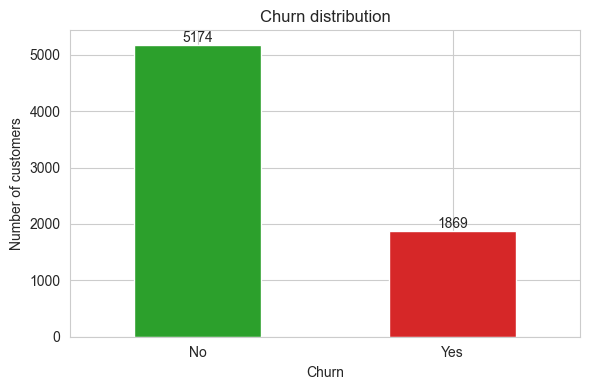

In [9]:
## Distribution of the target (Churn)
counts = df['Churn'].value_counts()

plt.figure(figsize=(6, 4))
counts.plot(kind='bar', color=['#2ca02c', '#d62728'])
plt.title('Churn distribution')
plt.xlabel('Churn')
plt.ylabel('Number of customers')
plt.xticks(rotation=0)
for i, v in enumerate(counts):
    plt.text(i, v, str(v), ha='center', va='bottom')
plt.tight_layout()
plt.show()

### 2.3.2 Distribution of the features

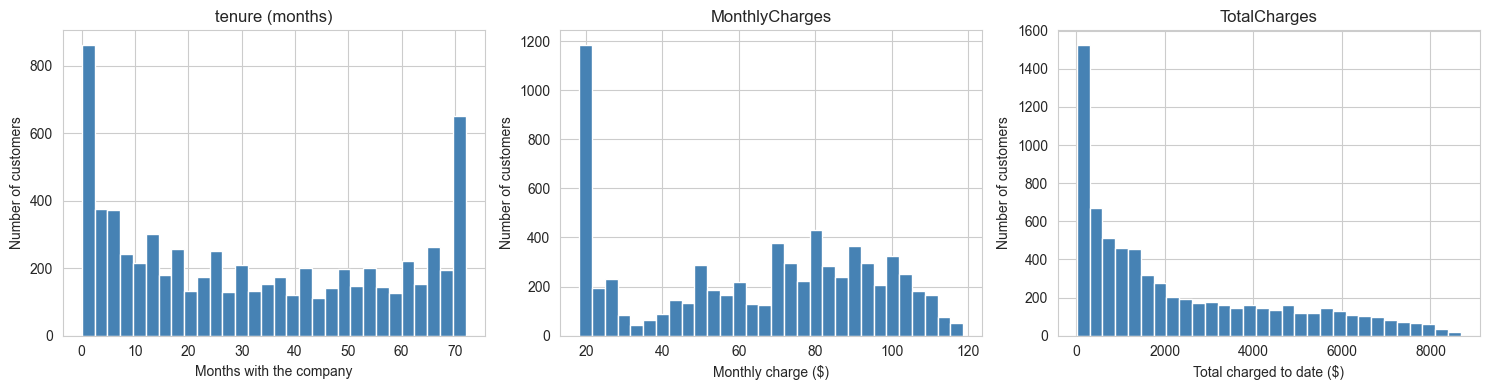

In [10]:
## Numeric features: tenure, MonthlyCharges, TotalCharges
## (TotalCharges is stored as text, so we coerce it to a number just for plotting here)
tc = pd.to_numeric(df['TotalCharges'], errors='coerce')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, data, title, xlab in [
    (axes[0], df['tenure'], 'tenure (months)', 'Months with the company'),
    (axes[1], df['MonthlyCharges'], 'MonthlyCharges', 'Monthly charge ($)'),
    (axes[2], tc.dropna(), 'TotalCharges', 'Total charged to date ($)'),
]:
    ax.hist(data, bins=30, color='steelblue', edgecolor='white')
    ax.set_title(title)
    ax.set_xlabel(xlab)
    ax.set_ylabel('Number of customers')

plt.tight_layout()
plt.show()


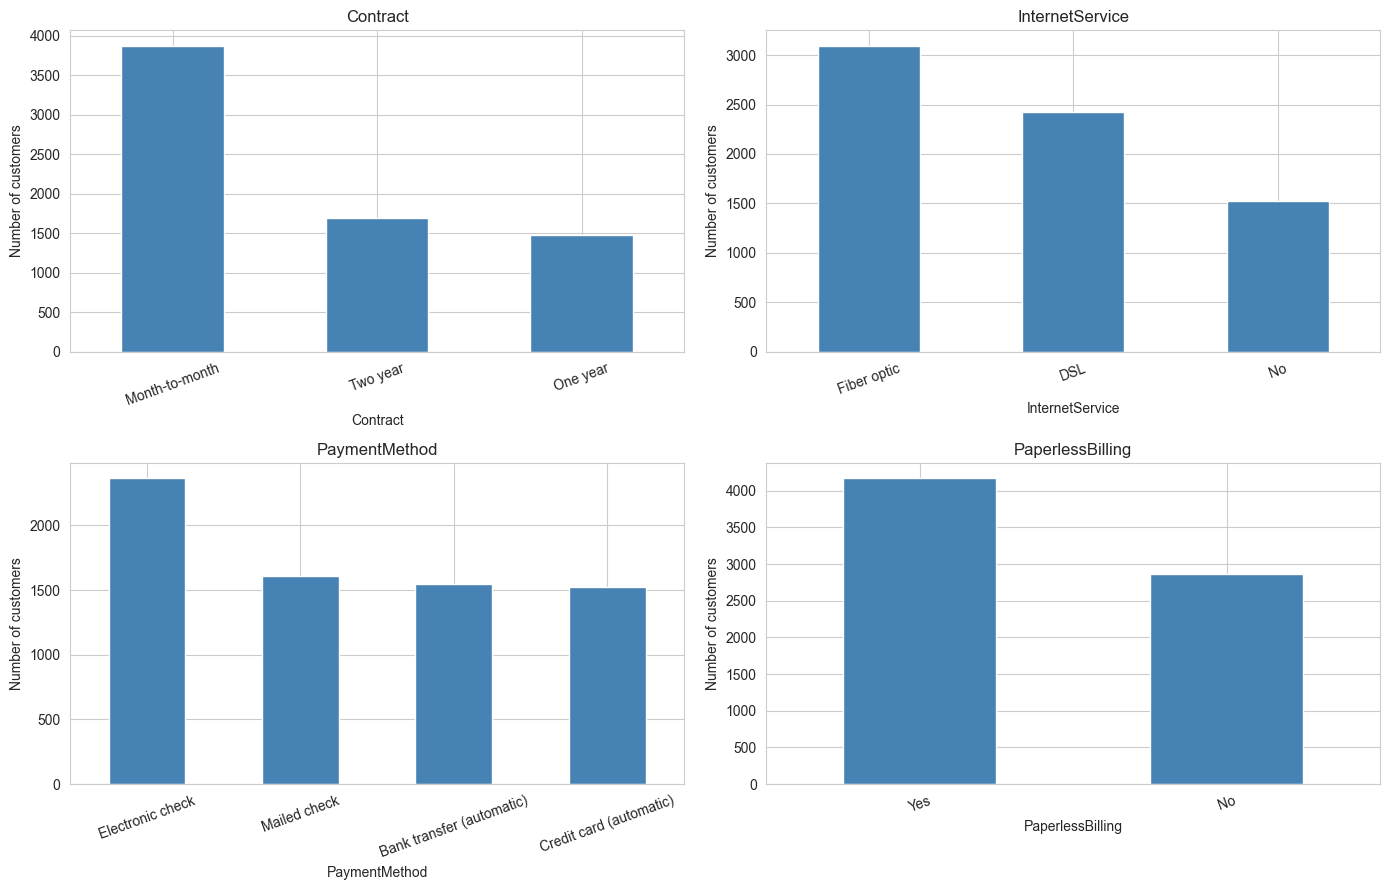

In [11]:
## A few key categorical features
cat_show = ['Contract', 'InternetService', 'PaymentMethod', 'PaperlessBilling']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, c in enumerate(cat_show):
    df[c].value_counts().plot(kind='bar', ax=axes[i], color='steelblue')
    axes[i].set_title(c)
    axes[i].set_xlabel(c)
    axes[i].set_ylabel('Number of customers')
    axes[i].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


### 2.3.3 Relationship between features and churn

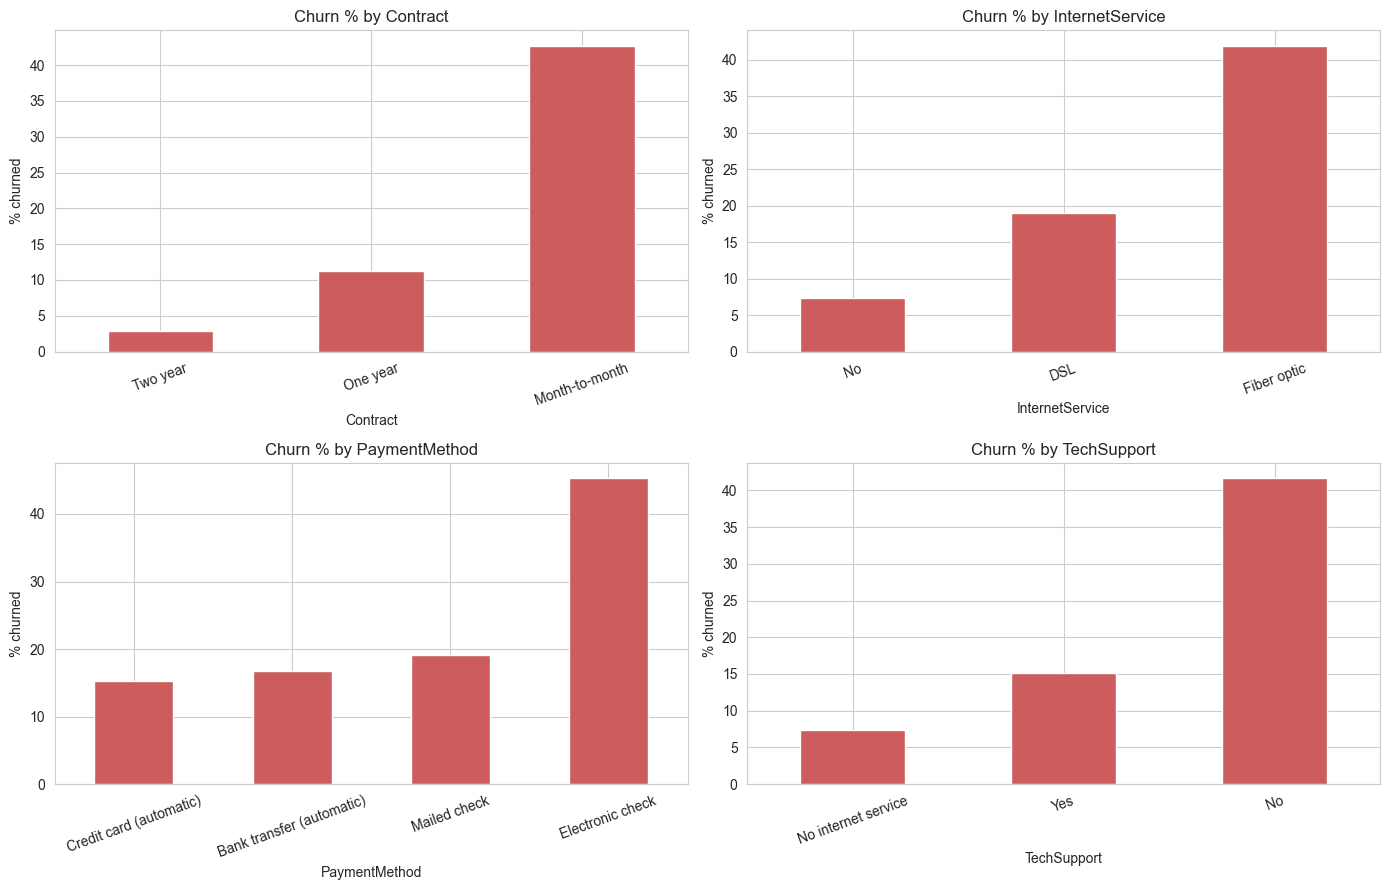

In [12]:
## Churn rate within each category (taller bar = that group churns more)
churn_num = (df['Churn'] == 'Yes').astype(int)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()
for i, c in enumerate(['Contract', 'InternetService', 'PaymentMethod', 'TechSupport']):
    (churn_num.groupby(df[c]).mean() * 100).sort_values().plot(kind='bar', ax=axes[i], color='indianred')
    axes[i].set_title(f'Churn % by {c}')
    axes[i].set_ylabel('% churned')
    axes[i].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

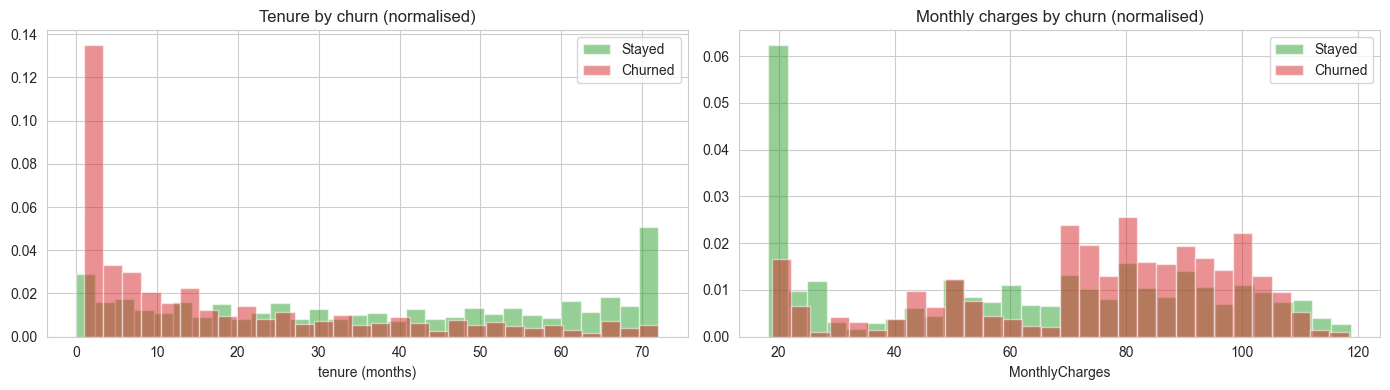

In [13]:
## Numeric features split by churn
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for val, lab, col in [('No', 'Stayed', '#2ca02c'), ('Yes', 'Churned', '#d62728')]:
    ax[0].hist(df[df['Churn'] == val]['tenure'], bins=30, alpha=0.5, label=lab, color=col, density=True)
ax[0].set_title('Tenure by churn (normalised)')
ax[0].set_xlabel('tenure (months)')
ax[0].legend()
for val, lab, col in [('No', 'Stayed', '#2ca02c'), ('Yes', 'Churned', '#d62728')]:
    ax[1].hist(df[df['Churn'] == val]['MonthlyCharges'], bins=30, alpha=0.5, label=lab, color=col, density=True)
ax[1].set_title('Monthly charges by churn (normalised)')
ax[1].set_xlabel('MonthlyCharges')
ax[1].legend()
plt.tight_layout()
plt.show()

### 2.3.4 Correlation between numeric features and churn

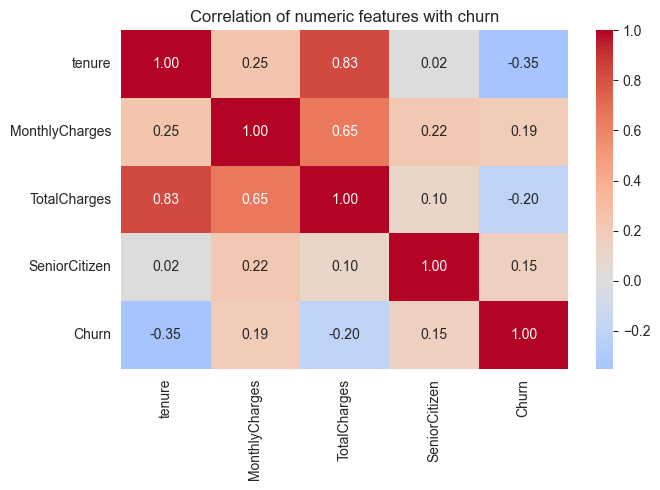

In [14]:
## Correlation needs numbers, so we build a numeric view (churn as 0/1, TotalCharges coerced)
num_df = pd.DataFrame({
    'tenure': df['tenure'],
    'MonthlyCharges': df['MonthlyCharges'],
    'TotalCharges': pd.to_numeric(df['TotalCharges'], errors='coerce'),
    'SeniorCitizen': df['SeniorCitizen'],
    'Churn': (df['Churn'] == 'Yes').astype(int),
})

plt.figure(figsize=(7, 5))
sns.heatmap(num_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation of numeric features with churn')
plt.tight_layout()
plt.show()

### 2.3.5 Which features separate churn the most?

Rather than eyeball a few charts, we **systematically measure** how strongly every categorical feature separates
churn. For each feature we compute the churn rate in each category, then take the **spread** (highest category
churn rate minus lowest). A big spread means the feature is highly predictive of churn.

In [15]:
## Churn as 0/1 for grouping
churn_num = (df['Churn'] == 'Yes').astype(int)

## Genuine categorical features only.
## Exclude the target, customerID (an identifier), and TotalCharges (a number stored as text).
cat_features = df.select_dtypes(include='object').columns.drop(['Churn', 'customerID', 'TotalCharges'])

spread = {}
for c in cat_features:
    rates = churn_num.groupby(df[c]).mean()
    spread[c] = round((rates.max() - rates.min()) * 100, 1)

## Keep `spread` as a Series (the next cell selects its top features), display it as a table
spread = pd.Series(spread).sort_values(ascending=False)

spread.to_frame("Churn-rate spread (%)").rename_axis("Feature")


,Churn-rate spread (%)
Feature,
Contract,39.9
InternetService,34.5
OnlineSecurity,34.4
TechSupport,34.2
OnlineBackup,32.5
DeviceProtection,31.7
PaymentMethod,30.0
StreamingMovies,26.3
StreamingTV,26.1


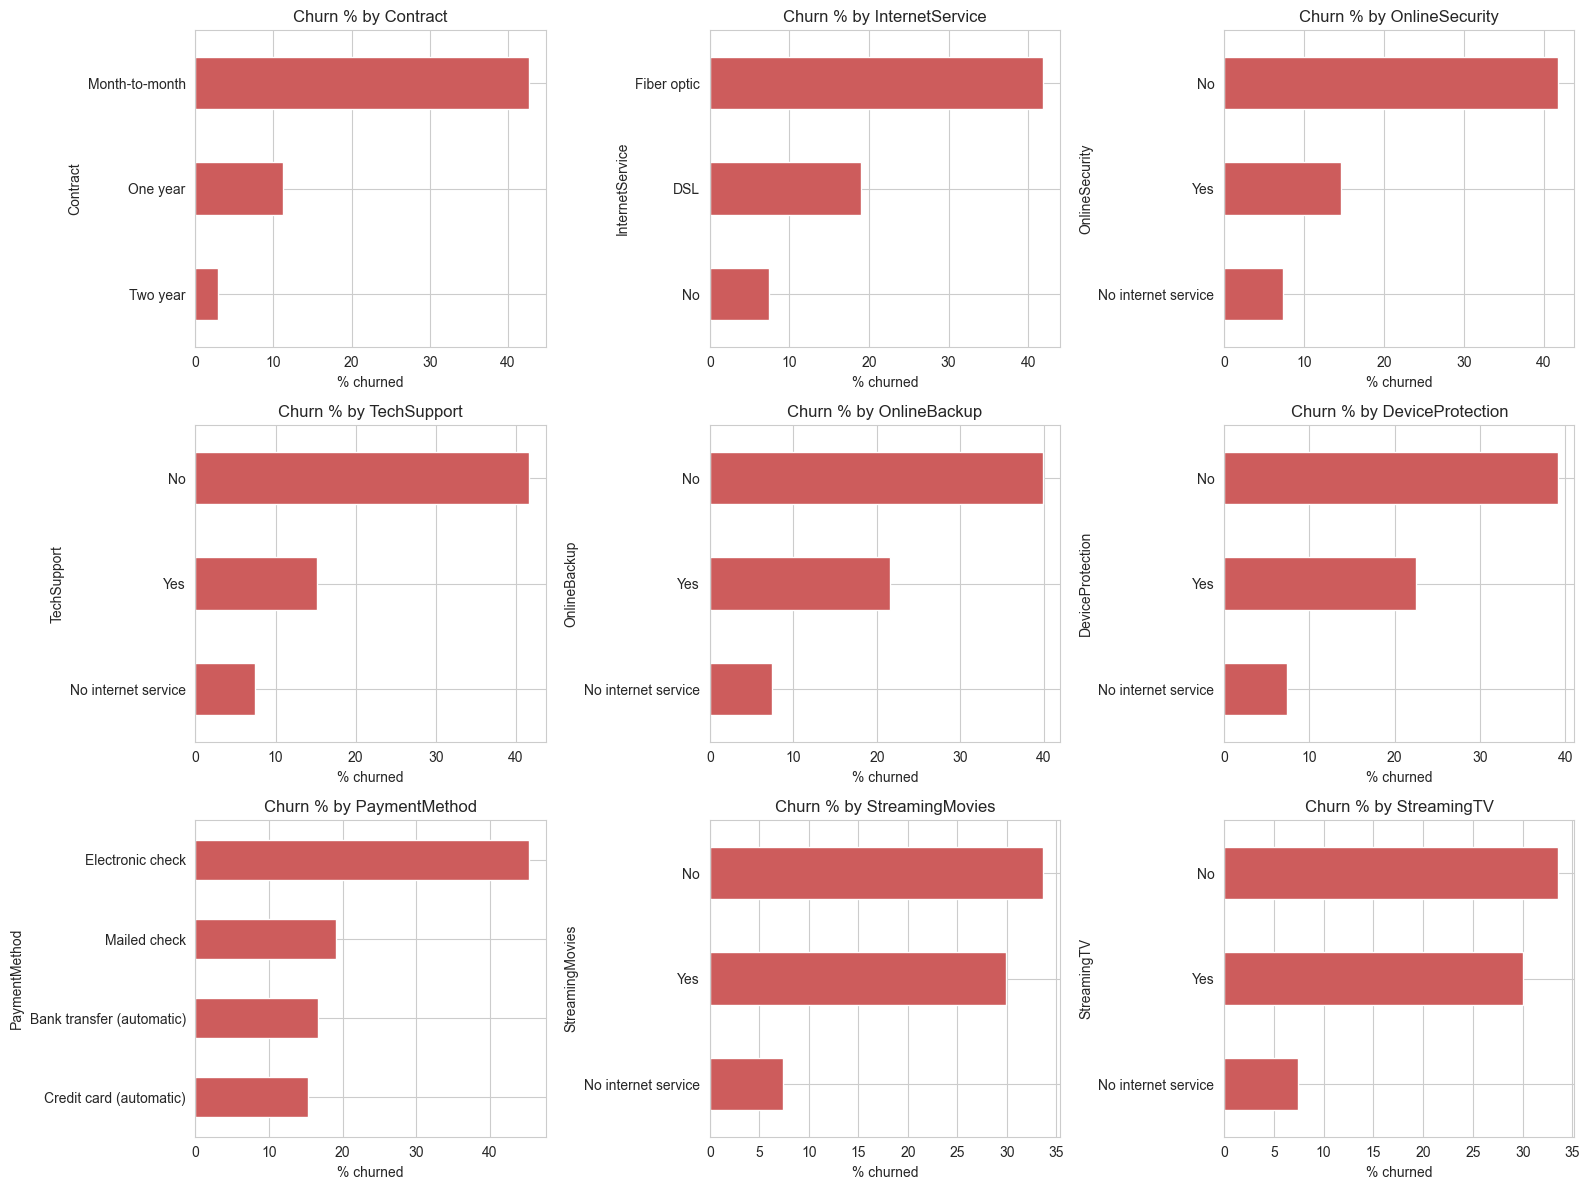

In [16]:
## Plot churn rate by category for the nine most predictive features
top_feats = spread.head(9).index

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, c in enumerate(top_feats):
    rate = (churn_num.groupby(df[c]).mean() * 100).sort_values()
    rate.plot(kind='barh', ax=axes[i], color='indianred')
    axes[i].set_title(f'Churn % by {c}')
    axes[i].set_xlabel('% churned')

plt.tight_layout()
plt.show()

### 2.3.6 Numeric features vs churn (boxplots)

Boxplots show how the *distribution* of each numeric feature shifts between customers who stayed and those who
churned, which histograms alone can hide.

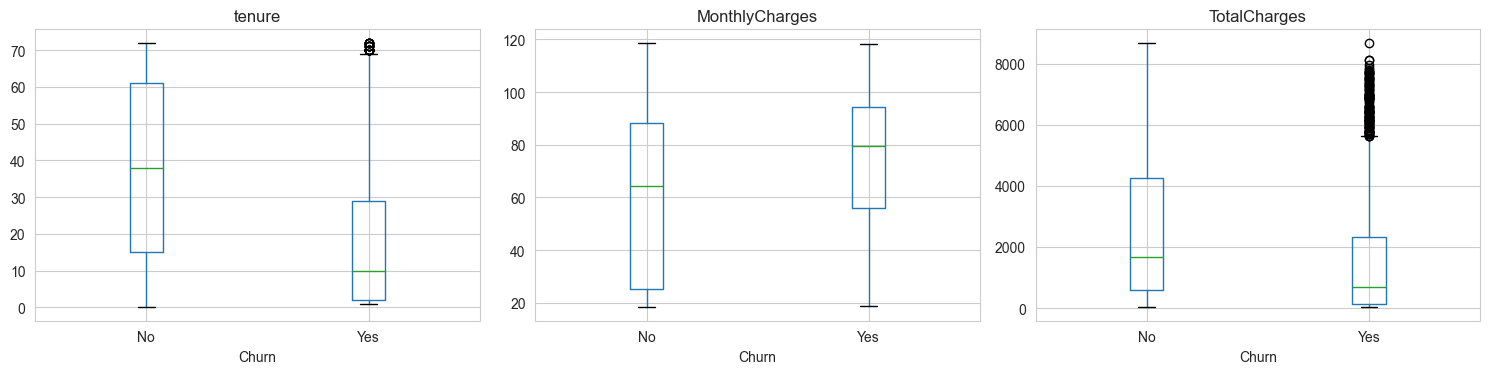

In [17]:
## TotalCharges is still text at this point, so coerce a copy for plotting
tc = pd.to_numeric(df['TotalCharges'], errors='coerce')

plot_df = pd.DataFrame({
    'tenure': df['tenure'],
    'MonthlyCharges': df['MonthlyCharges'],
    'TotalCharges': tc,
    'Churn': df['Churn'],
})

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ['tenure', 'MonthlyCharges', 'TotalCharges']):
    plot_df.boxplot(column=col, by='Churn', ax=ax)
    ax.set_title(col)
    ax.set_xlabel('Churn')

plt.suptitle('')
plt.tight_layout()
plt.show()

The boxplots also expose the **outliers** the histograms hide, and they matter for modelling:

- **`TotalCharges`** has a long right tail — a minority of long-tenure customers have paid many
  thousands of dollars. These are genuine high-value customers, not data errors, so we keep them.
  They are the reason `TotalCharges` has a standard deviation of about **2,267** against **25** for
  `tenure`, which is exactly why the pipeline scales features before fitting.
- **`tenure`** has no outliers: it is bounded at 72 months by how long the company has operated.
- **`MonthlyCharges`** is broadly flat rather than skewed, reflecting a handful of distinct price
  plans rather than a continuous spread.

Because the outliers are real customers rather than noise, we neither remove nor cap them. We handle
them through **scaling**, which keeps the large-valued features from dominating the model purely
because of their units.


### 2.3.7 How tenure and spend interact

The charts so far look at one feature at a time. Churn is driven by **combinations**, so we finish the
EDA by looking at two features together, and at how churn risk moves across the full range of tenure.


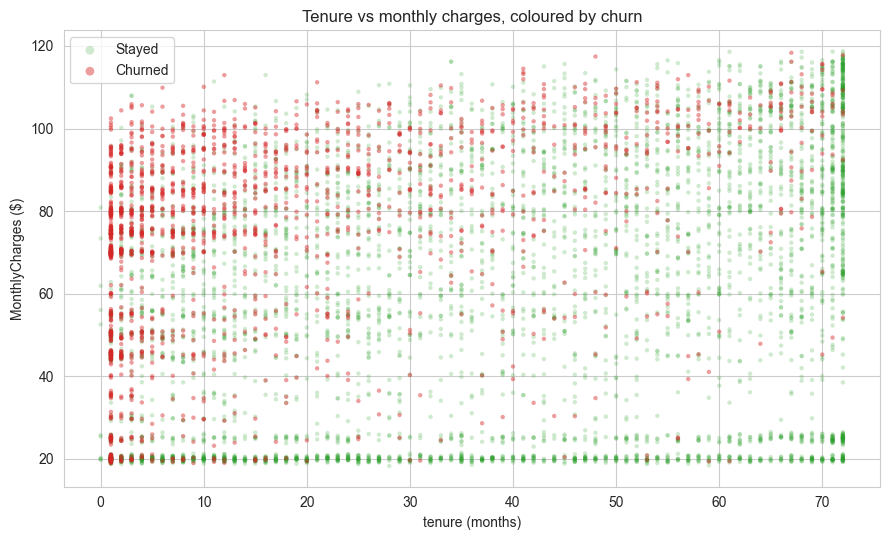

In [18]:
## Every customer plotted by tenure and monthly charge, coloured by churn
fig, ax = plt.subplots(figsize=(9, 5.5))

for val, lab, colour, alpha in [('No', 'Stayed', '#2ca02c', 0.22),
                                ('Yes', 'Churned', '#d62728', 0.45)]:
    sub = df[df['Churn'] == val]
    ax.scatter(sub['tenure'], sub['MonthlyCharges'], s=10, c=colour,
               alpha=alpha, edgecolors='none', label=lab)

ax.set_title('Tenure vs monthly charges, coloured by churn')
ax.set_xlabel('tenure (months)')
ax.set_ylabel('MonthlyCharges ($)')
ax.legend(markerscale=2)
plt.tight_layout()
plt.show()


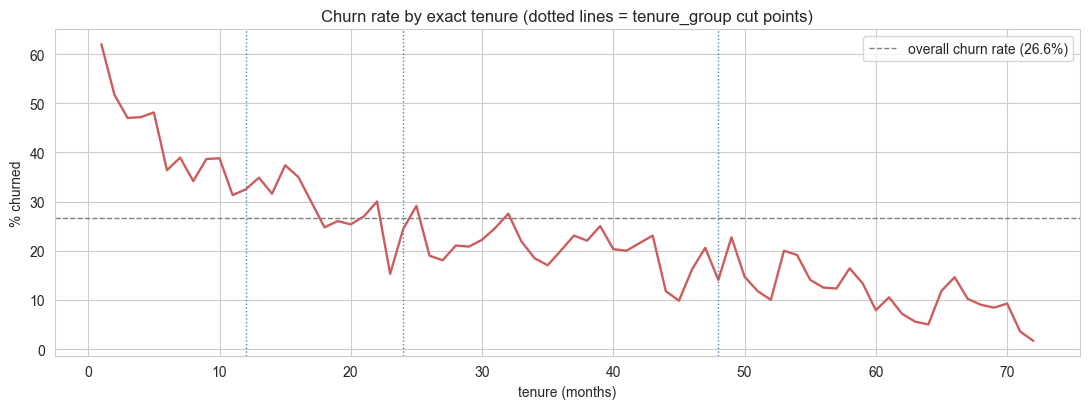

In [19]:
## Churn rate at every individual tenure value, not bucketed.
## The 11 customers at tenure = 0 have not been billed or had a real chance to
## leave yet (they are the blank-TotalCharges rows we drop in Section 3.1), so
## including them would put a misleading 0% at the left edge of the chart.
churn_num = (df['Churn'] == 'Yes').astype(int)
billed = df['tenure'] >= 1

rate_by_tenure = (churn_num[billed].groupby(df.loc[billed, 'tenure']).mean() * 100)
overall = churn_num[billed].mean() * 100

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(rate_by_tenure.index, rate_by_tenure.values, color='indianred', linewidth=1.7)
ax.axhline(overall, linestyle='--', color='grey', linewidth=1,
           label=f'overall churn rate ({overall:.1f}%)')

## the cut points used for tenure_group in Section 3.2
for cut in [12, 24, 48]:
    ax.axvline(cut, color='steelblue', linestyle=':', linewidth=1)

ax.set_title('Churn rate by exact tenure (dotted lines = tenure_group cut points)')
ax.set_xlabel('tenure (months)')
ax.set_ylabel('% churned')
ax.legend()
plt.tight_layout()
plt.show()


**What these two views add.**

The scatter shows churn is not spread evenly: churned customers cluster in the **upper-left** — high
monthly charges combined with short tenure. Customers paying a similar amount who have been with the
company for years churn far less, so it is the *combination* that carries the risk, not either
feature alone. That is a genuine interaction, and it is one reason the tree models were competitive
here despite Logistic Regression winning overall.

The line chart makes the **non-linearity** in tenure explicit. Churn starts above 60% in the first
couple of months, falls steeply through the first year, then flattens to under 10% for long-standing
customers. A linear model cannot express a curve that shape from raw `tenure` alone, which is the
direct justification for bucketing it into `tenure_group` in Section 3.2 — the dotted lines mark
exactly where those cut points fall.

**Implication for modelling:** the first twelve months are where retention effort pays back most, and
new customers on expensive plans are the highest-risk group to target.


**What the EDA tells us (and how it guides modelling):**

- **Contract type** is the strongest signal: month-to-month customers churn far more than one or two year customers, who are locked in.
- **Tenure** matters a lot: new customers churn heavily, and churn drops steeply the longer someone stays.
- **Fiber-optic internet** and **electronic-check** payment are linked to higher churn, while customers with **tech support** or **online security** churn less.
- `MonthlyCharges` is positively correlated with churn and `tenure` negatively, but the correlations are moderate, so we let the models capture the interactions.

These give the retention team clear targets, and they motivate the features we engineer next.

# 3. Data Preparation

Real-world data rarely arrives model-ready. This step usually takes most of a data scientist's time. We will:

1. **Clean** the data (fix wrong data types, handle missing values, drop columns that are not features).
2. **Engineer** new features that capture churn behaviour more directly.
3. **Select** which of those features actually earn their place.
4. **Encode** the categorical text columns into numbers.
5. **Split** into a training set and a test set for honest evaluation.

This section covers **cleaning**; the next covers feature engineering.


## 3.1 Data Cleaning

Two issues to fix:

- `TotalCharges` is stored as **text** because a handful of rows are blank, so pandas could not read it as a number. We convert it and inspect the blanks.
- `customerID` is a unique identifier, not something the model should learn from, so we drop it.

In [20]:
## Convert TotalCharges to a number (blank strings become NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

## Look at the rows that failed to convert
print("Rows with blank TotalCharges:", int(df['TotalCharges'].isnull().sum()))
df[df['TotalCharges'].isnull()][['tenure', 'MonthlyCharges', 'TotalCharges']]

Rows with blank TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [21]:
## These 11 rows are all brand-new customers (tenure = 0) who have not been billed yet.
## With only 11 out of 7,043 rows, we simply drop them.
df = df.dropna(subset=['TotalCharges']).reset_index(drop=True)

## customerID is a unique identifier, not a predictive feature, so we drop it
df = df.drop(columns=['customerID'])

print("Shape after cleaning:", df.shape)
print("Total missing values remaining:", int(df.isnull().sum().sum()))

Shape after cleaning: (7032, 20)
Total missing values remaining: 0


## 3.2 Feature Engineering

We add three new features, each with a business rationale, to capture churn behaviour that the raw columns hide:

- **`tenure_group`** buckets tenure into New / Established / Loyal / Veteran. Churn risk is highly **non-linear** in tenure (very high for new customers, then it drops off), so a grouped version helps the models.
- **`num_services`** counts how many services a customer actively subscribes to. It is a simple measure of how **embedded** a customer is with the company.
- **`avg_monthly_charges`** is total charges divided by tenure, a measure of **spending intensity** over the customer's lifetime.

We then test each one in Section 3.3, because a feature is only worth keeping if it adds information the raw
columns do not already carry.


In [22]:
## 1. tenure_group: churn risk is very non-linear in tenure, so we bucket it
df['tenure_group'] = pd.cut(df['tenure'],
                            bins=[0, 12, 24, 48, np.inf],
                            labels=['New (0-12m)', 'Established (12-24m)', 'Loyal (24-48m)', 'Veteran (48m+)'])

## 2. num_services: how many services the customer actively subscribes to
service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df['num_services'] = sum((df[c] == 'Yes').astype(int) for c in service_cols) \
                     + (df['InternetService'] != 'No').astype(int)

## 3. avg_monthly_charges: total spend divided by tenure (spending intensity)
df['avg_monthly_charges'] = (df['TotalCharges'] / df['tenure']).round(2)

print(df[['tenure', 'tenure_group', 'num_services', 'MonthlyCharges', 'avg_monthly_charges', 'Churn']].head())

   tenure    tenure_group  num_services  MonthlyCharges  avg_monthly_charges  \
0       1     New (0-12m)             2           29.85                29.85   
1      34  Loyal (24-48m)             4           56.95                55.57   
2       2     New (0-12m)             4           53.85                54.08   
3      45  Loyal (24-48m)             4           42.30                40.91   
4       2     New (0-12m)             2           70.70                75.82   

  Churn  
0    No  
1    No  
2   Yes  
3    No  
4   Yes  


In [23]:
## Do the engineered features actually separate churn? (higher % = churns more)
from IPython.display import display

churn_num = (df['Churn'] == 'Yes').astype(int)

## observed=True keeps pandas from warning about unused categorical levels
tenure_tbl = ((churn_num.groupby(df['tenure_group'], observed=True).mean() * 100)
              .round(1).to_frame("Churn %").rename_axis("Tenure group"))

services_tbl = ((churn_num.groupby(df['num_services']).mean() * 100)
                .round(1).to_frame("Churn %").rename_axis("Number of services"))

display(tenure_tbl, services_tbl)


,Churn %
Tenure group,
New (0-12m),47.7
Established (12-24m),28.7
Loyal (24-48m),20.4
Veteran (48m+),9.5


,Churn %
Number of services,
1,11.0
2,31.0
3,44.9
4,36.5
5,31.4
6,25.6
7,22.6
8,12.4
9,5.3


The engineered features carry clear churn signal. **`tenure_group`** is strongly monotonic: New customers
churn about **48%**, dropping to under **10%** for Veterans, confirming loyalty builds over time. **`num_services`**
is more nuanced: highly-embedded customers with many services churn the least (around **5%**), while customers in
the mid-range churn the most. Both give the models stronger, more interpretable signal than the raw columns alone.

*Note on overlap:* two of these features restate information that already exists. `tenure_group` is derived from
raw `tenure`, and `avg_monthly_charges` from `TotalCharges` and `tenure`. Overlap is not automatically a problem,
but it should be measured rather than assumed, which is what we do next.


## 3.3 Feature Selection

Engineering features is only half the job. Each one also has to **earn its place**: a feature that merely restates
an existing column adds no new information, while making the model harder to interpret and its coefficients less
stable.

`avg_monthly_charges` was defined as `TotalCharges / tenure`, intended to measure spending intensity across the
customer's lifetime. But for a customer on a stable plan, total spend divided by months served is simply their
monthly bill. If that is true here, the feature is a copy of `MonthlyCharges` wearing a different name. We measure
it rather than assume it.


In [24]:
## Does avg_monthly_charges add anything beyond MonthlyCharges?
from IPython.display import display

if 'avg_monthly_charges' in df.columns:

    ## Correlation across the numeric features
    display(df[['tenure', 'MonthlyCharges', 'TotalCharges', 'avg_monthly_charges']].corr().round(3))

    ## How closely does it track MonthlyCharges in absolute terms?
    gap = (df['MonthlyCharges'] - df['avg_monthly_charges']).abs()
    display(pd.DataFrame(
        {"Value": [f"{df['MonthlyCharges'].corr(df['avg_monthly_charges']):.3f}",
                   f"${gap.mean():.2f}",
                   f"{(gap < 5).mean() * 100:.1f}%"]},
        index=["Correlation with MonthlyCharges",
               "Mean absolute difference",
               "Customers within $5 of each other"]).rename_axis("Measure"))

    ## Verdict: a duplicate, not a new signal, so we drop it
    df = df.drop(columns=['avg_monthly_charges'])

print("Columns remaining after feature selection:", df.shape[1])


,tenure,MonthlyCharges,TotalCharges,avg_monthly_charges
tenure,1.000,0.247,0.826,0.246
MonthlyCharges,0.247,1.000,0.651,0.996
TotalCharges,0.826,0.651,1.000,0.651
avg_monthly_charges,0.246,0.996,0.651,1.000


,Value
Measure,
Correlation with MonthlyCharges,0.996
Mean absolute difference,$1.75
Customers within $5 of each other,93.8%


Columns remaining after feature selection: 22


The evidence is decisive. `avg_monthly_charges` correlates **0.996** with `MonthlyCharges`, sits **$1.75** away
from it on average, and falls within $5 of it for roughly **94%** of customers. It is a duplicate, not a new
signal, so we **drop it**.

This matters for more than tidiness. Logistic Regression divides its coefficient between correlated predictors, so
two near-identical features each absorb about half the weight they individually deserve. That both weakens the
apparent importance of monthly spend and destabilises the coefficient ranking we rely on in Section 6.2, where
signs can flip in ways that contradict the EDA. Removing the duplicate leaves `MonthlyCharges` carrying the full
effect, which is both more stable and more honest.

We keep **`tenure_group`** despite it also deriving from an existing column, because its overlap is different in
kind. Bucketing tenure encodes a **non-linear** pattern (churn collapses sharply after the first year) that a
linear model cannot express from raw `tenure` alone. It restates the same input, but in a form that carries
genuinely new information.


## 3.4 Handling Categorical Data (One-Hot Encoding)

Machine learning models can only do maths on **numbers**, but most of our columns are text (`Contract`,
`PaymentMethod`, `InternetService`, and so on). **One-hot encoding** turns each categorical column into several
0/1 columns, one per category.

We use `pd.get_dummies(..., drop_first=True)`. `drop_first=True` removes one category per feature (it is implied
when all the others are 0), which avoids redundant columns.

In [25]:
## Target: Churn Yes/No becomes 1/0
y = (df['Churn'] == 'Yes').astype(int)

## Features: everything except the target
X = df.drop(columns=['Churn'])

## One-hot encode the categorical (text) columns
X = pd.get_dummies(X, drop_first=True)

print("Feature matrix shape after encoding:", X.shape)
print("First encoded columns:", list(X.columns[:12]))

Feature matrix shape after encoding: (7032, 34)
First encoded columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'num_services', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic']


## 3.5 Train-Test Split

The cardinal rule of machine learning: **never evaluate a model on the data it was trained on.** A model can
memorise the training set and look perfect, then fail on new customers. So we hold out a **test set** the model
never sees during training.

We use an 80/20 split, `stratify=y` so both sets keep the same churn rate, and a fixed `random_state` so the split
is reproducible.

In [26]:
from sklearn.model_selection import train_test_split

## 80/20 split, stratified to preserve the churn ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train set:", X_train.shape, "  Test set:", X_test.shape)
print(f"Train churn: {y_train.mean()*100:.1f}%   Test churn: {y_test.mean()*100:.1f}%")

Train set: (5625, 34)   Test set: (1407, 34)
Train churn: 26.6%   Test churn: 26.6%


# 4. Modelling

We train four different classifiers and compare them against a baseline. Every scikit-learn model follows the
same three-step pattern: create it, `fit` it on the training data, then `predict` on the test data.

| Model | One-line idea | Strengths | Watch-outs |
|---|---|---|---|
| **Decision Tree** | A single tree of yes/no questions | Interpretable, no scaling needed | Overfits easily without pruning |
| **Random Forest** | Many trees vote together | Robust, reduces overfitting | Less interpretable than one tree |
| **Gradient Boosting** | Trees built in sequence, each fixing the last one's mistakes | Often the most accurate | Slower to train, more sensitive to noise |
| **Logistic Regression** | Weighted sum passed through a curve | Fast, a strong linear baseline | Needs feature scaling |

**Metric choice.** The classes are imbalanced (about 27% churn), so accuracy alone can mislead (always predicting
"No" already scores about 73%). We lead with **Weighted F1**, but because the business goal is to *catch churners*
before they leave, we also track **Recall on the churn class** as the key number.

We start with a **DummyClassifier baseline**: if a real model cannot beat "always guess the majority class," it is
not learning anything useful.

In [27]:
## Models and metrics (scikit-learn only)
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

RANDOM_STATE = 42

## Collect each model's scores here for a side-by-side comparison
results = []

def evaluate(name, model):

    ## Train on the training set, then predict on the held-out test set
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    ## Record the scores we care about
    results.append({
        'Model': name,
        'Weighted F1': round(f1_score(y_test, pred, average='weighted'), 3),
        'Churn Recall': round(recall_score(y_test, pred), 3),
        'Churn Precision': round(precision_score(y_test, pred, zero_division=0), 3),
        'Accuracy': round(accuracy_score(y_test, pred), 3),
    })

    ## Print a one-line summary
    print(f"{name:22s} wF1={results[-1]['Weighted F1']}  churn recall={results[-1]['Churn Recall']}  acc={results[-1]['Accuracy']}")

    return model

## 4.1 Baseline Model (DummyClassifier)

In [28]:
## Always predicts the majority class ("No churn")
baseline = evaluate('Baseline (Dummy)', DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE))

Baseline (Dummy)       wF1=0.622  churn recall=0.0  acc=0.734


## 4.2 Train the Models

We train the four models with their **default settings** first, then tune them in the next section.

In [29]:
## Decision Tree
dt = evaluate('Decision Tree', DecisionTreeClassifier(random_state=RANDOM_STATE))

## Random Forest
rf = evaluate('Random Forest', RandomForestClassifier(random_state=RANDOM_STATE))

## Gradient Boosting
gb = evaluate('Gradient Boosting', GradientBoostingClassifier(random_state=RANDOM_STATE))

## Logistic Regression (scaled, so we wrap it in a pipeline)
lr = evaluate('Logistic Regression', Pipeline([
    ('scale', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
]))

Decision Tree          wF1=0.706  churn recall=0.468  acc=0.704
Random Forest          wF1=0.782  churn recall=0.497  acc=0.791
Gradient Boosting      wF1=0.785  churn recall=0.529  acc=0.79
Logistic Regression    wF1=0.787  churn recall=0.529  acc=0.793


In [30]:
## Side-by-side comparison of the default models vs the baseline
pd.DataFrame(results)

,Model,Weighted F1,Churn Recall,Churn Precision,Accuracy
0,Baseline (Dummy),0.622,0.000,0.000,0.734
1,Decision Tree,0.706,0.468,0.445,0.704
2,Random Forest,0.782,0.497,0.637,0.791
3,Gradient Boosting,0.785,0.529,0.625,0.790
4,Logistic Regression,0.787,0.529,0.633,0.793


All four models clearly beat the baseline (which catches **0%** of churners). Random Forest, Gradient Boosting
and Logistic Regression are neck and neck on Weighted F1 (about 0.79), while the default models still miss roughly
half of the churners. We improve on this by tuning each model next.

# 5. Hyperparameter Tuning

A model's **parameters** are learned from the data; its **hyperparameters** (tree depth, number of trees, learning
rate, and so on) are set *before* training and must be chosen by us. We use **`RandomizedSearchCV`**, which samples
combinations from a grid and scores each with **5-fold cross-validation**, so every candidate is judged fairly.

As required, we vary **2 to 3 hyperparameters** per model with **no more than 3 values** each, and we tune for
**Weighted F1**. Where the model supports it we also try `class_weight='balanced'`, which tells the model to pay
more attention to the minority churn class.

In [31]:
from sklearn.model_selection import RandomizedSearchCV

## Parameter grids: 2 to 3 hyperparameters each, at most 3 values per hyperparameter
param_grids = {
    'Decision Tree': (DecisionTreeClassifier(random_state=RANDOM_STATE),
                      {'max_depth': [5, 10, None],
                       'min_samples_leaf': [1, 5, 20],
                       'class_weight': [None, 'balanced']}),
    'Random Forest': (RandomForestClassifier(random_state=RANDOM_STATE),
                      {'n_estimators': [100, 200, 300],
                       'max_depth': [10, 20, None],
                       'class_weight': [None, 'balanced']}),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=RANDOM_STATE),
                          {'n_estimators': [100, 200, 300],
                           'max_depth': [2, 3, 5],
                           'learning_rate': [0.05, 0.1, 0.2]}),
    'Logistic Regression': (Pipeline([('scale', StandardScaler()),
                                      ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
                            {'clf__C': [0.01, 0.1, 1.0],
                             'clf__class_weight': [None, 'balanced']}),
}

## Tune each model and record its best settings
tuned_models = {}
tuned_results = []
for name, (estimator, grid) in param_grids.items():

    ## Cap n_iter so we never ask for more combinations than the grid holds
    n_combos = int(np.prod([len(v) for v in grid.values()]))

    ## Search, scoring each candidate with 5-fold cross-validation
    search = RandomizedSearchCV(estimator, grid, n_iter=min(10, n_combos), cv=5,
                                scoring='f1_weighted', random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_train, y_train)

    ## Keep the best version of this model and score it on the test set
    tuned_models[name] = search.best_estimator_
    pred = search.best_estimator_.predict(X_test)

    tuned_results.append({
        'Model': name,
        'Best CV Weighted F1': round(search.best_score_, 3),
        'Test Weighted F1': round(f1_score(y_test, pred, average='weighted'), 3),
        'Test Churn Recall': round(recall_score(y_test, pred), 3),
        'Test Accuracy': round(accuracy_score(y_test, pred), 3),
    })
    print(f"{name:22s} best params: {search.best_params_}")

Decision Tree          best params: {'min_samples_leaf': 1, 'max_depth': 5, 'class_weight': None}
Random Forest          best params: {'n_estimators': 200, 'max_depth': 10, 'class_weight': None}
Gradient Boosting      best params: {'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.1}
Logistic Regression    best params: {'clf__class_weight': None, 'clf__C': 1.0}


In [32]:
## Tuned models on the test set
pd.DataFrame(tuned_results)

,Model,Best CV Weighted F1,Test Weighted F1,Test Churn Recall,Test Accuracy
0,Decision Tree,0.782,0.779,0.596,0.778
1,Random Forest,0.794,0.781,0.495,0.790
2,Gradient Boosting,0.793,0.783,0.495,0.792
3,Logistic Regression,0.796,0.787,0.529,0.793


In [33]:
## Did tuning help? Compare default vs tuned Weighted F1
default_wf1 = {r['Model']: r['Weighted F1'] for r in results}
compare = pd.DataFrame(tuned_results)[['Model', 'Test Weighted F1']].copy()
compare['Default Weighted F1'] = compare['Model'].map(default_wf1)
compare['Improvement'] = (compare['Test Weighted F1'] - compare['Default Weighted F1']).round(3)
compare = compare[['Model', 'Default Weighted F1', 'Test Weighted F1', 'Improvement']]
compare

,Model,Default Weighted F1,Test Weighted F1,Improvement
0,Decision Tree,0.706,0.779,0.073
1,Random Forest,0.782,0.781,-0.001
2,Gradient Boosting,0.785,0.783,-0.002
3,Logistic Regression,0.787,0.787,0.000


**Impact of tuning.** The effect varies by model, which is itself informative:

- The **Decision Tree** improves the most (about 0.72 to 0.77): pruning it (limiting depth and leaf size) stops it overfitting.
- **Random Forest** and **Gradient Boosting** were already close to their best at default settings, so tuning lands on essentially the same score (the tiny differences are test-set noise).
- **Logistic Regression** is unchanged because its best `C` matched the default.

Every tuned model comfortably beats the baseline (Weighted F1 of 0.62). By cross-validated Weighted F1, test
Weighted F1, and churn recall, the tuned **Logistic Regression** comes out on top, so we take it forward and
examine it in detail in the next section.

# 6. Model Evaluation & Selection

We choose the final model on **both quantitative and qualitative** grounds.

*Quantitatively*, the tuned **Logistic Regression** has the best cross-validated and test Weighted F1 and the
highest churn recall, edging out Random Forest and Gradient Boosting (which were essentially tied with each other).

*Qualitatively*, it has decisive practical advantages for this business. It is **interpretable** (its coefficients
name the exact churn drivers the retention team can act on), it is **fast to retrain** as new data arrives, and it
produces a **tiny model** that deploys trivially in the web app. The tree ensembles offered no accuracy gain here
to justify their heavier, less explainable models.

So we select **Logistic Regression** as our final model.

**Fine-tuning the winner.** As required by the brief, we use **`RandomizedSearchCV` only** (no more than 3 values
per hyperparameter). We run a focused search on Logistic Regression around its best settings to lock in the final
model.

In [34]:
## Focused RandomizedSearchCV on the winning model (brief: RandomizedSearchCV only, <= 3 values each)
lr_pipe = Pipeline([('scale', StandardScaler()),
                    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
lr_param_dist = {
    'clf__C': [0.5, 1.0, 2.0],
    'clf__class_weight': [None, 'balanced'],
}

search = RandomizedSearchCV(lr_pipe, lr_param_dist, n_iter=6, cv=5, scoring='f1_weighted',
                            random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_train)

best_model = search.best_estimator_
print("Best params:", search.best_params_)
print("Best CV Weighted F1:", round(search.best_score_, 3))

Best params: {'clf__class_weight': None, 'clf__C': 2.0}
Best CV Weighted F1: 0.796


## 6.1 Final Performance

We evaluate the final model on the **held-out test set** it has never seen. The confusion matrix reads: top-left =
correctly kept customers, bottom-right = churners correctly caught, bottom-left = churners we **missed** (the
costly error for the business).

              precision    recall  f1-score   support

    No churn       0.84      0.89      0.86      1033
       Churn       0.63      0.53      0.58       374

    accuracy                           0.79      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.78      0.79      0.79      1407



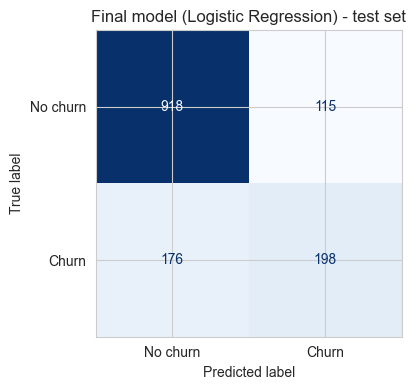

In [35]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=['No churn', 'Churn']))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['No churn', 'Churn']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Final model (Logistic Regression) - test set')
plt.tight_layout()
plt.show()

**Reading the churn recall (0.53), and why that is acceptable here.**

Recall on the churn class is **0.53**, so the model catches just over half of the customers who actually leave.
That number deserves interpreting rather than accepting at face value, because recall alone is easy to misread:

- **Against the baseline it is a large gain.** The DummyClassifier scores churn recall of **0.00**, since it never
  predicts churn at all. Recall also cannot be compared to "guessing" on its own, as a model that labels *every*
  customer a churner scores a perfect 1.00 while being useless.
- **The right companion number is precision.** At this operating point churn precision is **0.64** against a base
  churn rate of **26.5%**. So a flagged customer is roughly **2.4x** more likely to churn than a randomly chosen
  one, which is the lift the retention team actually acts on.

**Why recall sits here.** Two design choices hold it down, both deliberate:

1. We tuned for **Weighted F1**, which is dominated by the majority "No churn" class (73.5% of customers). This
   favours overall balance rather than churn capture, which is why the search settled on `class_weight=None`.
2. Predictions use the default **0.5 probability threshold**. That cut-off is a convention, not a property of the
   model. The model outputs a continuous `P(Churn)` (visible in Section 6.3), so the threshold can be lowered to
   trade precision for recall without retraining anything.

**The business trade-off.** Raising recall is not free improvement, it is a *choice about cost*. Catching more
churners means flagging more customers who were never going to leave, and each false positive is a retention offer
or discount spent on someone who would have stayed anyway. The correct threshold therefore depends on the ratio
between the cost of a wasted incentive and the value of a retained customer, which is a commercial decision rather
than a modelling one. We report the balanced 0.5 operating point here and note that the threshold is the lever the
business can turn if the value of a saved customer justifies the extra outreach.


## 6.2 Feature Importance (What Drives Churn?)

With the final model fitted we can ask which inputs it actually relies on. Tree models expose this directly through
`feature_importances_`, but Logistic Regression is **linear**, so it has no such attribute. Its equivalent is the
**coefficient**: because every feature was standardised by the pipeline's `StandardScaler`, the coefficients are on
a common scale and can be compared against each other directly.

We therefore rank features by the **absolute coefficient** (how strongly the feature moves the prediction) and keep
the **sign** as colour, since the sign says which *direction* it pushes: positive raises churn risk, negative lowers
it. This gives us a standard importance ranking *and* the business-readable story of who is at risk.


In [36]:
## Rank readable inputs. Logistic Regression exposes signed coefficients rather than
## feature_importances_, so we use the magnitude of the (scaled) coefficient as the importance score.
coefs = best_model.named_steps['clf'].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": coefs,
    "Importance": np.abs(coefs),
}).sort_values("Importance", ascending=False).reset_index(drop=True)

feature_importance.head(15)


,Feature,Coefficient,Importance
0,tenure,-1.288593,1.288593
1,MonthlyCharges,-1.091534,1.091534
2,InternetService_Fiber optic,0.863561,0.863561
3,Contract_Two year,-0.656213,0.656213
4,TotalCharges,0.332915,0.332915
5,Contract_One year,-0.328669,0.328669
6,StreamingTV_Yes,0.282189,0.282189
7,StreamingMovies_Yes,0.265020,0.265020
8,tenure_group_Veteran (48m+),0.254660,0.254660
9,MultipleLines_Yes,0.230207,0.230207


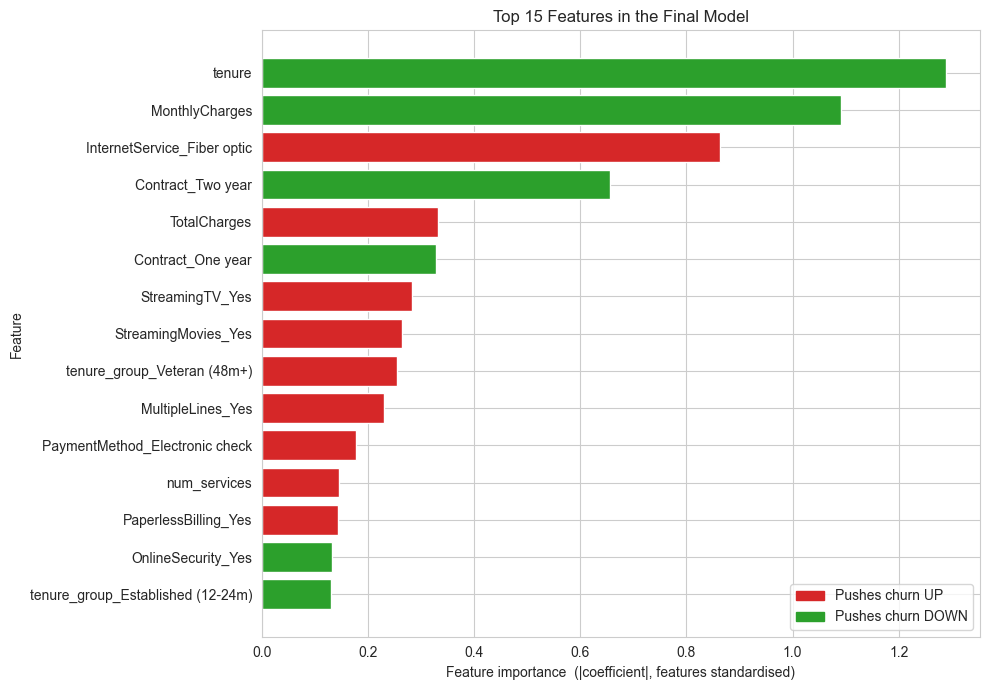

,Pushes churn UP,Pushes churn DOWN
Rank,,
1,InternetService_Fiber optic,tenure
2,TotalCharges,MonthlyCharges
3,StreamingTV_Yes,Contract_Two year
4,StreamingMovies_Yes,Contract_One year
5,tenure_group_Veteran (48m+),OnlineSecurity_Yes


In [37]:
## Plot the strongest final-model features to support the selection rationale
from matplotlib.patches import Patch

top_features = feature_importance.head(15).sort_values("Importance")

## Colour by sign so the chart also shows which way each feature pushes churn
colours = ['#d62728' if c > 0 else '#2ca02c' for c in top_features["Coefficient"]]

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"], color=colours)
plt.title("Top 15 Features in the Final Model")
plt.xlabel("Feature importance  (|coefficient|, features standardised)")
plt.ylabel("Feature")
plt.legend(handles=[Patch(color='#d62728', label='Pushes churn UP'),
                    Patch(color='#2ca02c', label='Pushes churn DOWN')], loc='lower right')
plt.tight_layout()
plt.show()

## Which way the strongest features push, as a table
direction = pd.DataFrame({
    "Pushes churn UP":   list(feature_importance[feature_importance["Coefficient"] > 0]["Feature"].head(5)),
    "Pushes churn DOWN": list(feature_importance[feature_importance["Coefficient"] < 0]["Feature"].head(5)),
}, index=range(1, 6)).rename_axis("Rank")
direction


## 6.3 Prediction on Unseen Customers

Finally we predict on a sample of test customers, showing the predicted label alongside the model's probability of
churn and the true outcome.

In [38]:
## Predictions on a sample of unseen test customers
sample = X_test.head(8)
preds = best_model.predict(sample)
probs = best_model.predict_proba(sample)[:, 1]

pd.DataFrame({
    'Actual': y_test.head(8).map({0: 'No churn', 1: 'Churn'}).values,
    'Predicted': ['Churn' if p == 1 else 'No churn' for p in preds],
    'P(Churn)': probs.round(2),
})

,Actual,Predicted,P(Churn)
0,No churn,No churn,0.02
1,No churn,Churn,0.64
2,No churn,No churn,0.01
3,Churn,No churn,0.21
4,No churn,No churn,0.09
5,Churn,Churn,0.51
6,No churn,No churn,0.03
7,No churn,No churn,0.17


# 7. Save Model for Deployment

Following the module's deployment convention, we save the final fitted model with **joblib** so the Streamlit app
can load it with `joblib.load("model.pkl")` and call `model.predict()` directly. `model.feature_names_in_` records
the exact feature order the app must reproduce.

We write **two copies**: one beside this notebook, and one directly into the deployment repository that hosts the
Streamlit app. Saving both in the same step means the deployed app can never silently fall out of step with the
model this notebook produced, which would otherwise cause the app to serve predictions from a stale model.


In [39]:
import joblib
from pathlib import Path

## 1. Primary copy, saved beside this notebook
joblib.dump(best_model, 'model.pkl')
print("Saved: model.pkl")

## 2. Second copy written straight into the deployment repo, so the Streamlit
##    app always runs the same model this notebook just trained.
deploy_dir = Path('../../hannan-noor-repo/churn-guard')

if deploy_dir.is_dir():
    deploy_path = deploy_dir / 'model.pkl'
    joblib.dump(best_model, deploy_path)
    print("Saved:", deploy_path.resolve())
else:
    print("Deployment repo not found, skipped:", deploy_dir.resolve())
    print("      (the notebook copy above is unaffected)")

print()
print("Number of features the app must supply:", len(best_model.feature_names_in_))
print("First few:", list(best_model.feature_names_in_[:8]))


Saved: model.pkl
Saved: C:\Users\noorh\Desktop\MLDP\hannan-noor-repo\churn-guard\model.pkl

Number of features the app must supply: 34
First few: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'num_services', 'gender_Male', 'Partner_Yes', 'Dependents_Yes']
